# General

In [7]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [2]:
# cifar-10 images are 32x32 RGB
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train = y_train.ravel()
y_test = y_test.ravel()
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)
classes = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
train_idx, val_idx = train_test_split(np.arange(len(y_train)), test_size=0.15, random_state=42, stratify=y_train)
print('Training:', len(train_idx), 'Validation:', len(val_idx), 'Test:', len(y_test))

Training: 42500 Validation: 7500 Test: 10000


# Models

In [4]:
def build_model(filters=(32, 64), first_kernel=3, dropout=0.25, dense_units=(512,), optimizer='adam', learning_rate=0.001):
    model = keras.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))
    for i, units in enumerate(filters):
        model.add(layers.Conv2D(units, first_kernel if i == 0 else 3, padding='same', activation='relu'))
        model.add(layers.Conv2D(units, 3, padding='same', activation='relu'))
        model.add(layers.MaxPooling2D(pool_size=(2, 2)))
        model.add(layers.Dropout(dropout))
    model.add(layers.Flatten())
    for units in dense_units:
        model.add(layers.Dense(units, activation='relu'))
        model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))
    opt = keras.optimizers.get(optimizer)
    opt.learning_rate = learning_rate
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return model


configs = [
    # two-block reference
    {'name': 'base', 'filters': (32, 64), 'first_kernel': 3, 'dropout': 0.25, 'dense_units': (512,), 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 128},
    # + third block
    {'name': 'extra_block', 'filters': (32, 64, 128), 'first_kernel': 3, 'dropout': 0.25, 'dense_units': (512,), 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 128},
    # 5x5 kernel
    {'name': '5x_kernel', 'filters': (32, 64, 128), 'first_kernel': 5, 'dropout': 0.25, 'dense_units': (512,), 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 128},
    # increased dropout
    {'name': 'dropout', 'filters': (32, 64, 128), 'first_kernel': 5, 'dropout': 0.35, 'dense_units': (512,), 'optimizer': 'adam', 'learning_rate': 0.001, 'epochs': 20, 'batch_size': 128},
    # more dense units + rmsprop instead of adam
    {'name': 'rmsprop', 'filters': (32, 64, 128), 'first_kernel': 5, 'dropout': 0.35, 'dense_units': (256, 128), 'optimizer': 'rmsprop', 'learning_rate': 0.0005, 'epochs': 30, 'batch_size': 200}
]
pd.DataFrame(configs)

,name,filters,first_kernel,dropout,dense_units,optimizer,learning_rate,epochs,batch_size
0,base,"(32, 64)",3,0.25,"(512,)",adam,0.0010,20,128
1,extra_block,"(32, 64, 128)",3,0.25,"(512,)",adam,0.0010,20,128
2,5x_kernel,"(32, 64, 128)",5,0.25,"(512,)",adam,0.0010,20,128
3,dropout,"(32, 64, 128)",5,0.35,"(512,)",adam,0.0010,20,128
4,rmsprop,"(32, 64, 128)",5,0.35,"(256, 128)",rmsprop,0.0005,30,200


# Training

In [5]:
def plot_history(history, name):
    history = pd.DataFrame(history)
    
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axs, ['accuracy', 'loss']):
        ax.plot(np.arange(1, len(history) + 1), history[metric], label='Training')
        ax.plot(np.arange(1, len(history) + 1), history[f'val_{metric}'], label='Validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

W0000 00:00:1792077149.991484  835203 cpu_allocator_impl.cc:82] Allocation of 522240000 exceeds 10% of free system memory.
W0000 00:00:1792077150.319649  835203 cpu_allocator_impl.cc:82] Allocation of 522240000 exceeds 10% of free system memory.
I0000 00:00:1792077152.276467  887972 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6383__.39
I0000 00:00:1792077160.454077  887973 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6383__.39
W0000 00:00:1792077164.990288  835203 cpu_allocator_impl.cc:82] Allocation of 92160000 exceeds 10% of free system memory.


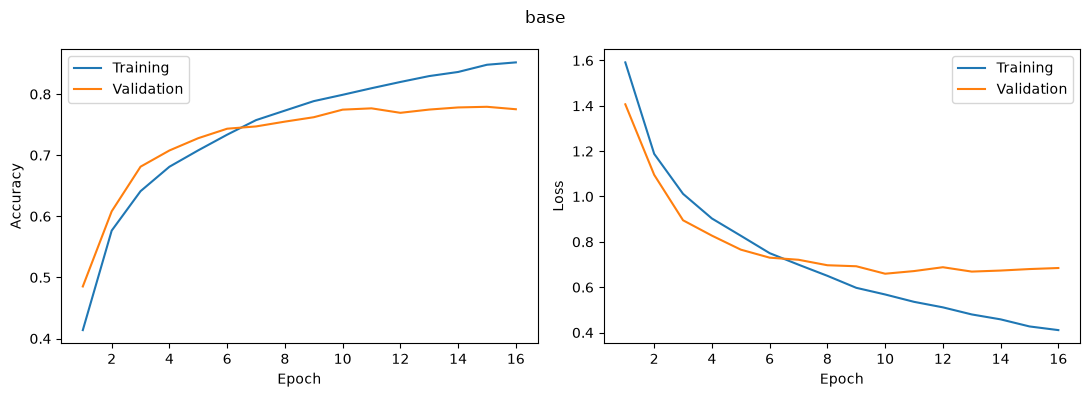

I0000 00:00:1792077265.299447  887973 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_39866__.50
I0000 00:00:1792077276.618497  887973 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_39866__.50


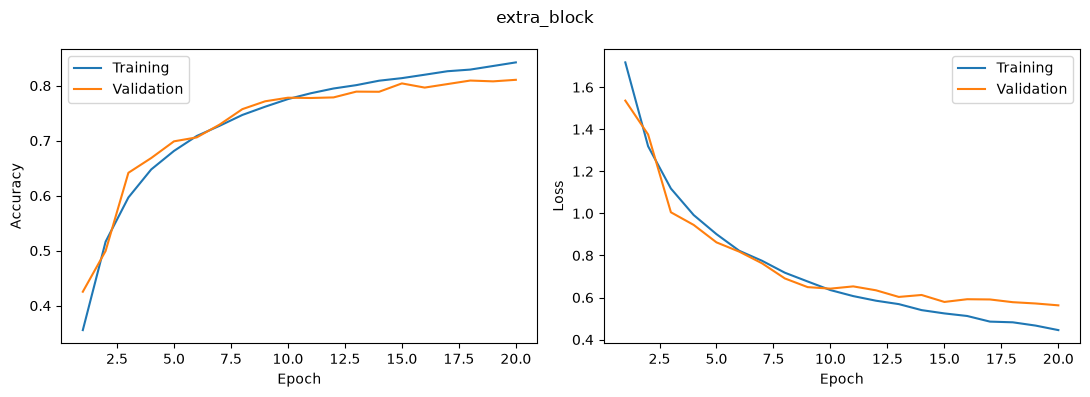

I0000 00:00:1792077418.645513  887970 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81132__.50
I0000 00:00:1792077428.966189  887969 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_81132__.50


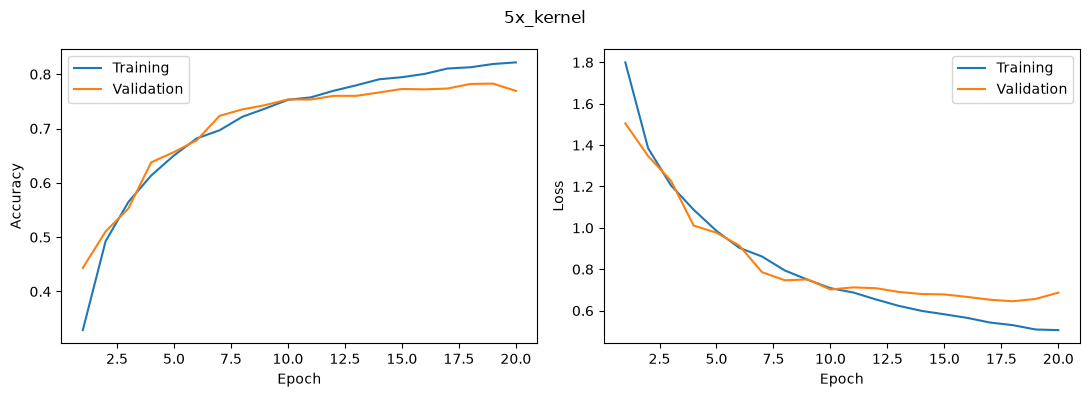

I0000 00:00:1792077576.300061  887972 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_122257__.50
I0000 00:00:1792077586.124513  887971 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_122257__.50


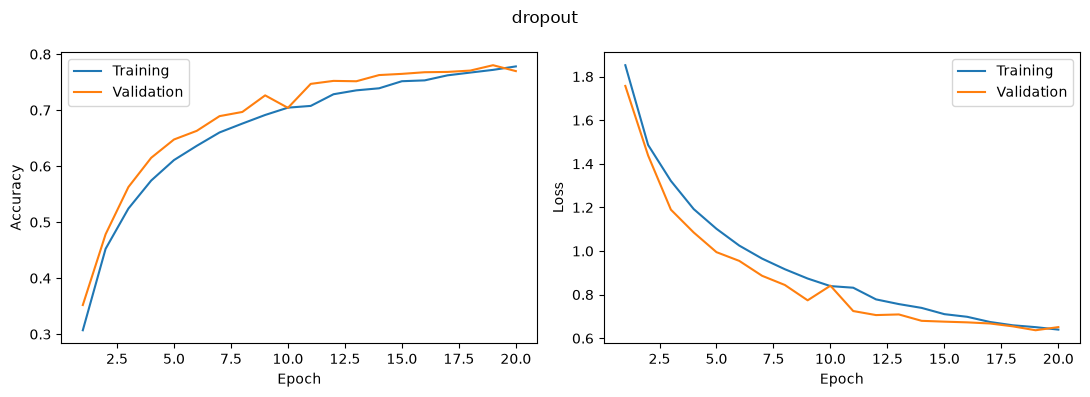

I0000 00:00:1792077732.231111  887971 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_162876__.52
I0000 00:00:1792077746.510280  887971 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_162876__.52


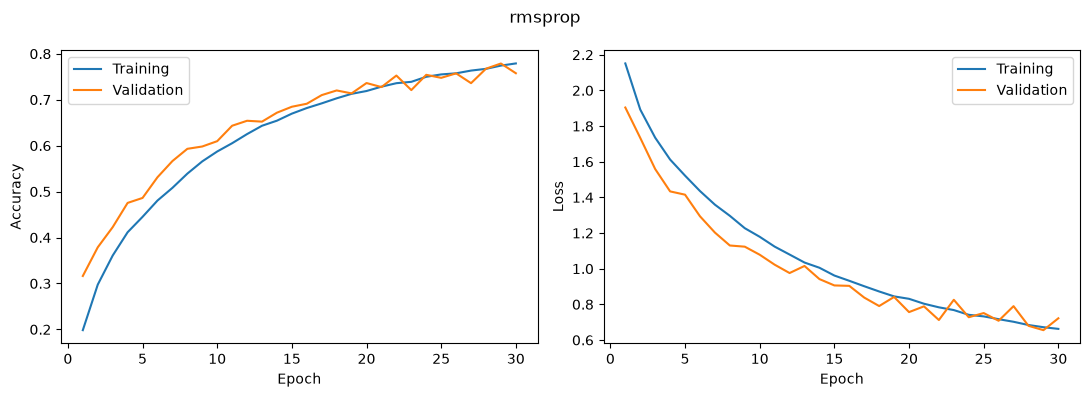

In [8]:
results = []
for config in configs:
    keras.backend.clear_session()
    keras.utils.set_random_seed(42)
    
    name = config['name']
    model = build_model(**{k: v for k, v in config.items() if k not in ['name', 'epochs', 'batch_size']})
    if name == 'baseline':
        model.summary()
        
    history = model.fit(
        x_train[train_idx], y_train_cat[train_idx],
        validation_data=(x_train[val_idx], y_train_cat[val_idx]),
        epochs=config['epochs'], batch_size=config['batch_size'], verbose=0,
        callbacks=[
            keras.callbacks.ModelCheckpoint(f'models/{name}.keras', monitor='val_loss', save_best_only=True),
            keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
        ]
    )
    model = keras.models.load_model(f'models/{name}.keras')
    
    val_loss, val_accuracy = model.evaluate(x_train[val_idx], y_train_cat[val_idx], verbose=0)
    loss, accuracy = model.evaluate(x_test, y_test_cat, verbose=0)
    results.append({
        **config,
        'epochs_run': len(history.epoch),
        'parameters': model.count_params(),
        'best_epoch': int(np.argmin(history.history['val_loss']) + 1),
        'val_loss': val_loss,
        'val_accuracy': val_accuracy,
        'test_loss': loss,
        'test_accuracy': accuracy}
    )
    plot_history(history.history, name)

In [9]:
results = pd.DataFrame(results)
display(results)

,name,filters,first_kernel,dropout,dense_units,optimizer,learning_rate,epochs,batch_size,epochs_run,parameters,best_epoch,val_loss,val_accuracy,test_loss,test_accuracy
0,base,"(32, 64)",3,0.25,"(512,)",adam,0.0010,20,128,16,2168362,10,0.659483,0.774533,0.678803,0.7688
1,extra_block,"(32, 64, 128)",3,0.25,"(512,)",adam,0.0010,20,128,20,1341226,20,0.562817,0.810667,0.598334,0.8055
2,5x_kernel,"(32, 64, 128)",5,0.25,"(512,)",adam,0.0010,20,128,20,1342762,18,0.645356,0.782000,0.663861,0.7839
3,dropout,"(32, 64, 128)",5,0.35,"(512,)",adam,0.0010,20,128,20,1342762,19,0.636711,0.780267,0.669452,0.7693
4,rmsprop,"(32, 64, 128)",5,0.35,"(256, 128)",rmsprop,0.0005,30,200,30,847274,29,0.655187,0.778800,0.667843,0.7752


# Saving

In [10]:
best = results.sort_values('val_accuracy', ascending=False).iloc[0]

model = keras.models.load_model(f"models/{best['name']}.keras")
model.save('models/lab4_best.keras')
Path('models/lab4_best.json').write_text(model.to_json())
model.save_weights('models/lab4_best.weights.h5')

loaded_model = keras.models.load_model('models/lab4_best.keras')
np.testing.assert_allclose(model.predict(x_test[:20], verbose=0), loaded_model.predict(x_test[:20], verbose=0), atol=1e-6)

print('Best validation model:', best['name'])
print('Loaded model test scores:', loaded_model.evaluate(x_test, y_test_cat, verbose=0))

Best validation model: extra_block
Loaded model test scores: [0.5983337759971619, 0.8054999709129333]


# Test images

In [16]:
def predict_calc_acc(model, imgs, labels, names):
    probabilities = loaded_model.predict(imgs, verbose=0)
    predictions = probabilities.argmax(axis=1)
    table = pd.DataFrame({
        'image': names,
        'class': [classes[int(label)] for label in labels],
        'prediction': [classes[label] for label in predictions],
        'confidence': probabilities.max(axis=1)
    })
    table['correct'] = table['class'] == table['prediction']
    print(f"Accuracy on {name}: {table['correct'].mean():.2%}")

    rows = 5
    cols = int(np.ceil(len(imgs) / rows))
    fig, axs = plt.subplots(cols, rows, figsize=(12, 3 * cols), squeeze=False)
    for ax in axs.flat:
        ax.axis('off')
    for i, ax in enumerate(axs.flat):
        img = imgs[i].reshape(32, 32, 3)
        ax.imshow(img)
        ax.set_title(
            f"{table.iloc[i]['class']} --> {table.iloc[i]['prediction']}",
            fontsize=9,
            color='green' if table.iloc[i]['correct'] else 'red'
        )
    plt.tight_layout()
    plt.show()
    
    return table

Accuracy on rmsprop: 90.00%


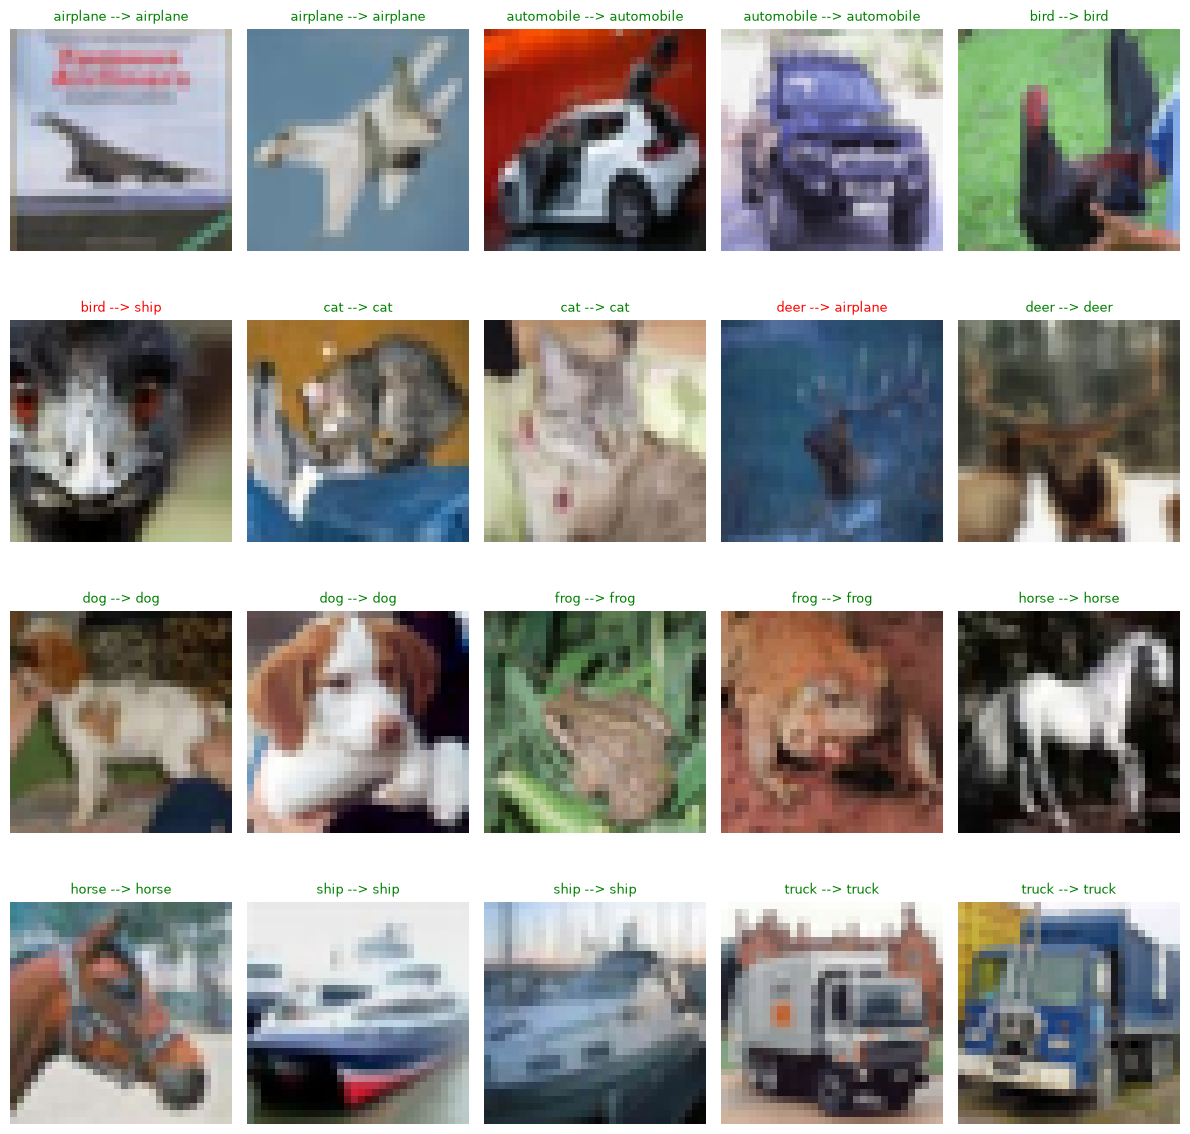

In [17]:
indices = np.concatenate([np.flatnonzero(y_test == i)[:2] for i in range(10)])
test_results = predict_calc_acc(loaded_model, x_test[indices], y_test[indices], indices)

# New images

Accuracy on rmsprop: 80.00%


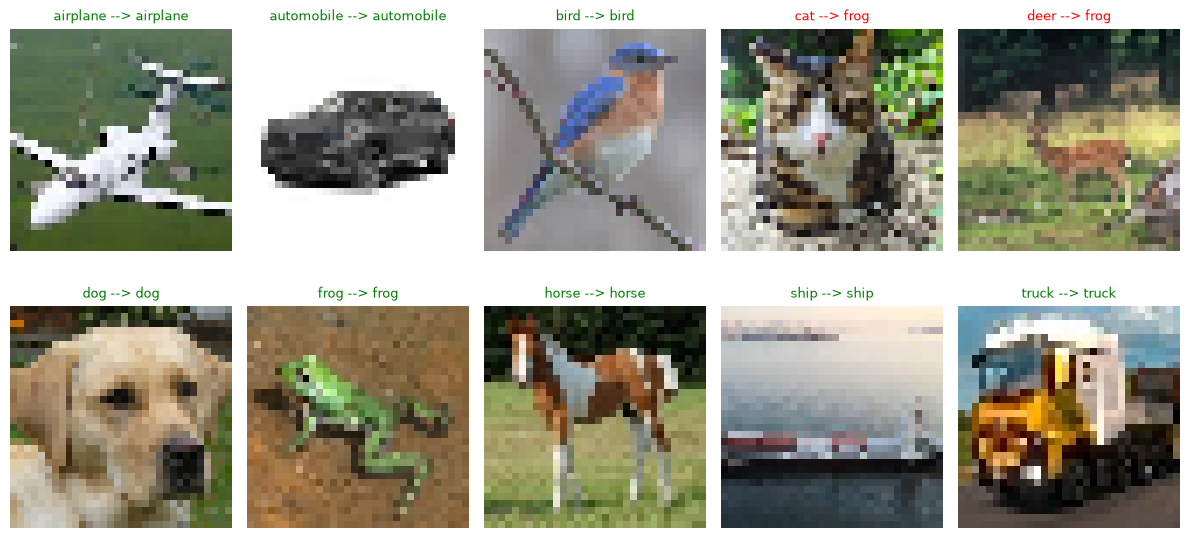

In [18]:
img_files = sorted([p for p in Path('images').iterdir()])
imgs = np.array([image.img_to_array(image.load_img(fname, target_size=(32, 32))) for fname in img_files]) / 255.0
img_labels = [classes.index(fname.stem) for fname in img_files]
new_results = predict_calc_acc(loaded_model, imgs, img_labels, [p.name for p in img_files])

# Summary

Порівняно 5 конфігурацій згорткової мережі на CIFAR-10. Для всіх використано однаковий поділ: 42 500 навчальних, 7 500 валідаційних і 10 000 тестових зображень. За валідаційною точністю обрано `extra_block`: **81.07%** на валідації та **80.55%** на тестовій вибірці. Тестові втрати становили 0.5983. Для кожної конфігурації зберігалася модель із найменшими валідаційними втратами; для `extra_block` це епоха 20.

Додавання третього згорткового блока підвищило валідаційну точність із 77.45% (`base`) до 81.07% (`extra_block`). Збільшення першого ядра до 5x5 дало 78.20% (`5x_kernel`), підвищення Dropout - 78.03% (`dropout`). Остання конфігурація `rmsprop` отримала 77.88%. У ній одночасно змінено оптимізатор, повнозв'язні шари, розмір пакета та кількість епох, тому цей результат не можна пояснити лише зміною оптимізатора. Dropout і рання зупинка використовувалися для обмеження перенавчання, але збільшення Dropout не покращило результат у цьому запуску.

На 20 показаних тестових зображеннях обрана модель отримала **90%**, на 10 зовнішніх - **80%**. Ці невеликі набори оцінюються окремо від повної тестової вибірки та не використовувалися для вибору моделі. Модель збережено у форматі `.keras`, також збережено архітектуру та ваги окремо. Після завантаження збіг прогнозів перевірено порівнянням із початковою моделлю.